# Pergunta 4 — Matrículas em classes comuns nas redes pública e privada

**Pergunta:** Qual a parcela das matrículas da educação especial em classes comuns e como ela difere entre a rede pública e a privada?

A comparação considera os anos de 2015, 2020 e 2025, com dados das Sinopses Estatísticas da Educação Básica do INEP.

## 1. Dados utilizados

A tabela reúne, para cada rede e ano, as matrículas em classes comuns e exclusivas. A rede pública inclui as dependências federal, estadual e municipal.

Em 2015 e 2020 foram usadas as tabelas 1.40 e 1.46 das Sinopses; em 2025, as tabelas 1.61 e 1.68.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

caminho = Path("pergunta4_dados_limpos_inep.csv")

if not caminho.exists():
    raise FileNotFoundError("Coloque o CSV na mesma pasta do notebook.")

# Cada linha do arquivo corresponde a uma rede em um dos três anos.
dados = pd.read_csv(caminho, encoding="utf-8-sig")
dados["total_matriculas"] = dados["classes_comuns"] + dados["classes_exclusivas"]

# Conferimos se as duas redes somam o total nacional informado pelo INEP.
totais_por_ano = dados.groupby("ano")["total_matriculas"].sum()
assert totais_por_ano.to_dict() == {2015: 930683, 2020: 1308900, 2025: 2458159}
assert len(dados) == 6 and not dados.duplicated(["ano", "rede"]).any()

display(dados.sort_values(["ano", "rede"]).reset_index(drop=True))

,ano,rede,classes_comuns,classes_exclusivas,total_matriculas
0,2015,Privada,47364,131572,178936
1,2015,Pública,703619,48128,751747
2,2020,Privada,81101,117295,198396
3,2020,Pública,1071774,38730,1110504
4,2025,Privada,232753,119374,352127
5,2025,Pública,2065252,40780,2106032


## 2. Percentual em classes comuns

Para comparar as redes, dividimos as matrículas em classes comuns pelo total de matrículas da educação especial **dentro de cada rede**. Também calculamos a diferença entre os percentuais, em pontos percentuais.

In [2]:
# Percentual de matrículas em classes comuns em cada rede.
dados["percentual_comuns"] = (
    dados["classes_comuns"] / dados["total_matriculas"] * 100
)

comparacao = dados.pivot(
    index="ano", columns="rede", values="percentual_comuns"
).sort_index()

comparacao["Diferença (p.p.)"] = comparacao["Pública"] - comparacao["Privada"]

display(comparacao.round(2))

rede,Privada,Pública,Diferença (p.p.)
ano,,,
2015,26.47,93.60,67.13
2020,40.88,96.51,55.63
2025,66.10,98.06,31.96


## 3. Evolução por rede

O gráfico mostra o percentual de matrículas em classes comuns nas duas redes. Cada ponto corresponde a um ano disponível na base; as linhas apenas ligam esses valores.

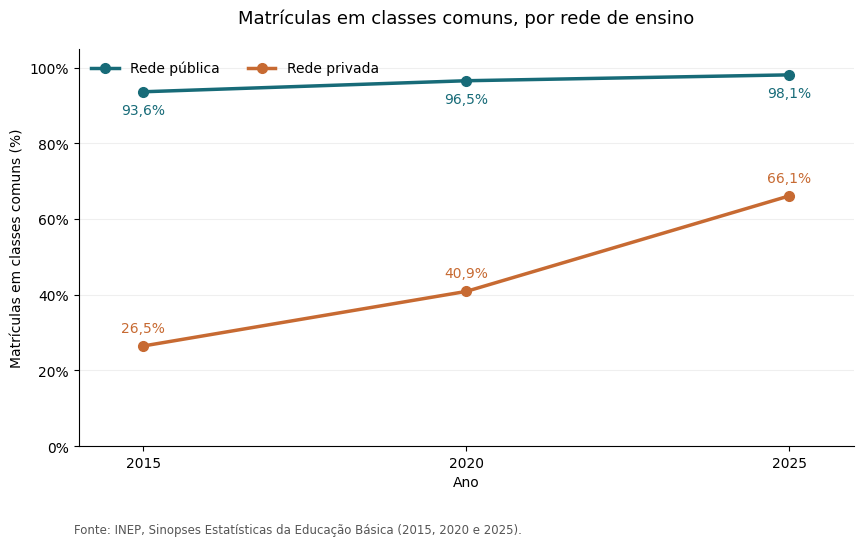

In [3]:
anos = [2015, 2020, 2025]
cores = {"Pública": "#176B78", "Privada": "#C76A32"}

figura, eixo = plt.subplots(figsize=(10, 5.6))

for rede in ["Pública", "Privada"]:
    dados_rede = dados[dados["rede"] == rede].sort_values("ano")

    eixo.plot(
        dados_rede["ano"], dados_rede["percentual_comuns"],
        marker="o", markersize=7, linewidth=2.5,
        color=cores[rede], label=f"Rede {rede.lower()}"
    )

    # Os valores ao lado dos pontos facilitam a leitura dos três anos.
    for _, linha in dados_rede.iterrows():
        deslocamento = -16 if rede == "Pública" else 10
        eixo.annotate(
            f'{linha["percentual_comuns"]:.1f}%'.replace(".", ","),
            (linha["ano"], linha["percentual_comuns"]),
            xytext=(0, deslocamento), textcoords="offset points",
            ha="center", fontsize=10, color=cores[rede]
        )

eixo.set_title("Matrículas em classes comuns, por rede de ensino", fontsize=13, pad=18)
eixo.set_xlabel("Ano")
eixo.set_ylabel("Matrículas em classes comuns (%)")
eixo.set_xticks(anos)
eixo.set_xlim(2014, 2026)
eixo.set_ylim(0, 105)
eixo.set_yticks(range(0, 101, 20))
eixo.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:.0f}%"))
eixo.grid(axis="y", alpha=0.2)
eixo.set_axisbelow(True)
eixo.spines[["top", "right"]].set_visible(False)
eixo.legend(loc="upper left", frameon=False, ncol=2)

figura.text(
    0.12, 0.015,
    "Fonte: INEP, Sinopses Estatísticas da Educação Básica (2015, 2020 e 2025).",
    fontsize=8.5, color="#555555"
)
figura.subplots_adjust(bottom=0.17, top=0.88)
plt.savefig("pergunta4_grafico_redes.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. Leitura dos resultados

A parcela de matrículas em classes comuns aumentou nas duas redes. Na **rede pública**, passou de **93,6% em 2015 para 98,1% em 2025**. Na **rede privada**, foi de **26,5% para 66,1%** no mesmo período.

A diferença entre as redes caiu de **67,1 para 32,0 pontos percentuais**. Mesmo assim, o percentual da rede privada continuou menor em 2025.

Esses números mostram onde os alunos estão matriculados, mas não indicam, por si só, a qualidade do atendimento. A rede privada também inclui instituições que oferecem ensino em classes exclusivas.

*Os dados cobrem três anos específicos, não todos os anos entre 2015 e 2025.*

**Fonte:** [INEP — Sinopses Estatísticas da Educação Básica](https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/sinopses-estatisticas/educacao-basica).